<a href="https://colab.research.google.com/github/muhammadhasbiashiddiqi/PM-mesinLearning/blob/main/KKnTugas1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Memuat dataset
df = pd.read_csv('/content/drive/MyDrive/PM/voice.csv')

# Memisahkan fitur dan label
X = df.drop('label', axis=1)
y = df['label']

# Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Normalisasi fitur (karena k-NN berbasis jarak)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. Membuat dan melatih model k-NN (default k=5)
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

# Evaluasi model
y_pred = knn.predict(X_test_scaled)
print("Akurasi (k=5):", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Akurasi (k=5): 0.9810725552050473
              precision    recall  f1-score   support

      female       0.98      0.98      0.98       297
        male       0.98      0.98      0.98       337

    accuracy                           0.98       634
   macro avg       0.98      0.98      0.98       634
weighted avg       0.98      0.98      0.98       634



Nilai k terbaik adalah 7 dengan akurasi 0.9826


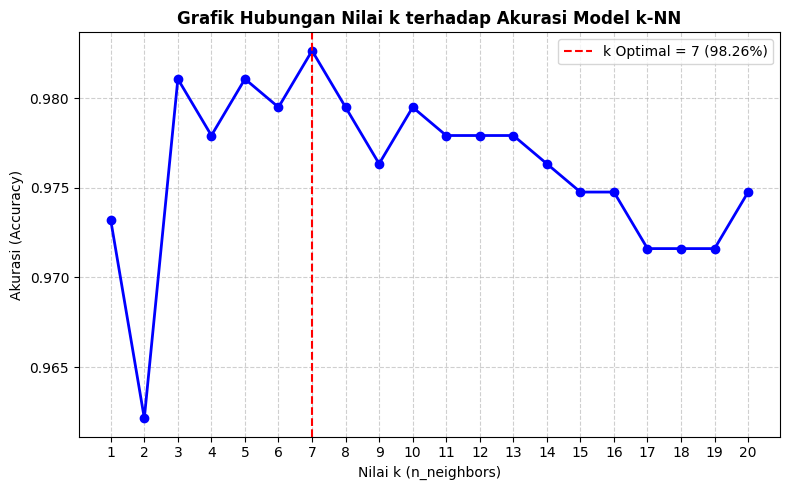

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# Menguji nilai k dari 1 sampai 20
k_values = range(1, 21)
accuracies = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    y_pred = knn.predict(X_test_scaled)
    accuracies.append(accuracy_score(y_test, y_pred))

# Menemukan k terbaik
best_k = k_values[np.argmax(accuracies)]
print(f"Nilai k terbaik adalah {best_k} dengan akurasi {max(accuracies):.4f}")

# Membuat Grafik Analisis
plt.figure(figsize=(8, 5))
plt.plot(k_values, accuracies, marker='o', linestyle='-', color='b', linewidth=2, markersize=6)
plt.title('Grafik Hubungan Nilai k terhadap Akurasi Model k-NN', fontsize=12, fontweight='bold')
plt.xlabel('Nilai k (n_neighbors)', fontsize=10)
plt.ylabel('Akurasi (Accuracy)', fontsize=10)
plt.xticks(k_values)
plt.grid(True, linestyle='--', alpha=0.6)
plt.axvline(x=best_k, color='r', linestyle='--', label=f'k Optimal = {best_k} ({max(accuracies)*100:.2f}%)')
plt.legend()
plt.tight_layout()
plt.savefig('knn_accuracy_plot.png')
plt.show()